# 04 The scale story: tiles, inductors, cost, accuracy, energy

[![Open In Colab](https://colab.research.google.com/assets/colab/badge.svg)](https://colab.research.google.com/github/<owner>/dlnn-paper/blob/main/notebooks/04_scale_story.ipynb)

**What this notebook does.** It answers "what does it take to build a bigger one?" from the repo's own reports and cost model (no simulation here, only bookkeeping, so it runs in seconds):

* regenerates the BOM/PCB/assembly **cost model** (`hw/board/cost_model.py`) and checks it against the committed `hw/board/cost.json`;
* the **scaling tables**: tiles, inductors, board area and cost for width W in {8, 16, 32, 64} and depth D in {3, 4, 6}  (`inductors = 448 (D-1)(W/8)^2 + 112 (W/8)`);
* **accuracy against size** from the training reports (`models/*_report.json`) and the arena report (accuracy against operations);
* a labelled **energy / latency estimate** against a conventional ANN on a processor;
* writes `docs/artifacts/data/scale_story.json` and `board_cost.json`, the files the article's outcome charts read.

Everything priced here is an **ESTIMATE that needs a live JLCPCB quote**: unit prices are single readings of JLC part pages on 2026-11-03, the bare-PCB price and the Nucleo price are assumptions. The board is designed, not built, nothing is measured.

In [1]:
# Colab only: install the system tools, clone the repo, install the pinned Python requirements. Skipped everywhere else.
import sys
if 'google.colab' in sys.modules:
    import os, subprocess
    REPO_URL = "https://github.com/<owner>/dlnn-paper"      # TODO: replace with the real URL once the repo is public
    subprocess.run("apt-get -qq install -y ngspice iverilog", shell=True, check=True)
    if not os.path.isdir("/content/dlnn-paper"):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "/content/dlnn-paper"], check=True)
    os.chdir("/content/dlnn-paper")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

In [2]:
import os, sys, time, json
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists() and (p / "dlnn").is_dir())
os.chdir(ROOT); sys.path.insert(0, str(ROOT))          # run from the repo root so relative paths in the library resolve
import numpy as np
from dlnn import paper
from dlnn.paper import DATA, EXPECTED, WORK
T0 = time.time()
ENV = paper.banner("04 The scale story")

04 The scale story
  python: 3.12.3
  numpy: 2.5.4
  platform: Linux-6.18.44-fc-v233-x86_64-with-glibc2.39
  ngspice: ngspice-42 : Circuit level simulation program
  iverilog: Icarus Verilog version 12.0 (stable) ()
  node: v22.23.4
  colab: False
  Simulation of a design that is not built. Nothing here is a measurement.


In [3]:
import subprocess, pandas as pd
import matplotlib.pyplot as plt
rows = []
COST = paper.read_json("hw/board/cost.json")
ARENA = paper.read_json("models/arena/arena_report.json")
ENERGY = paper.read_json("models/arena/energy_refs.json")
print(COST["LABEL"])

ESTIMATE, needs a live JLCPCB quote; prices are single readings of JLC part pages on 2026-11-03, not quotes; not a commitment


## 1. Regenerate the cost model

The model counts the BOM per tile from `hw/board/params.json` (which resistor footprints the ternary weights populate), prices it from the stored JLC price tiers and adds PCB and assembly fees. It runs offline (`--refresh-prices` would re-read the JLC pages; not used here).

In [4]:
WK = WORK / "cost"; WK.mkdir(parents=True, exist_ok=True)
r = subprocess.run([sys.executable, "hw/board/cost_model.py", "--out", str(WK / "cost.json"), "--parts", str(WK / "parts.csv")], capture_output=True, text=True, cwd=ROOT)
print(r.stdout.strip().splitlines()[-1][:200] if r.stdout else r.stderr[-300:])
new = paper.read_json(WK / "cost.json")
same = all(COST.get(k) == v for k, v in new.items())             # the committed file also carries hand-written notes (extra keys)
print("regenerated cost.json identical to the committed one (all generated keys):", same, "| extra hand-written keys in the committed file:", sorted(set(COST) - set(new)), "| parts.csv identical:", paper.sha256_file(WK / "parts.csv") == paper.sha256_file("hw/board/parts.csv"))
assert same
demo = COST["demonstrator_width8_3tiles"]
print(f"width-8, 3-tile demonstrator: system total ${demo['system_total_usd']['economic_single_sided_tiles']:.0f} - ${demo['system_total_usd']['standard_double_sided_tiles']:.0f}"
      f", with 25 % contingency ${demo['system_total_usd_with_25pct_contingency']['low']:.0f} - ${demo['system_total_usd_with_25pct_contingency']['high']:.0f}  (ESTIMATE)")

{"economic_single_sided_tiles": 405.71, "standard_double_sided_tiles": 438.83} {'full_tile': 82.14, 'layer1_tile': 35.44}
regenerated cost.json identical to the committed one (all generated keys): True | extra hand-written keys in the committed file: ['M3b_notes'] | parts.csv identical: True
width-8, 3-tile demonstrator: system total $406 - $439, with 25 % contingency $507 - $549  (ESTIMATE)


## 2. Scaling tables

Layer 1 sees only the two I/Q input lines, so a width-W net needs W/8 layer-1 tiles with 2 of 8 lines populated (112 inductors each); every later layer needs (W/8)^2 full tiles (448 inductors each), because each input line has to be replicated on every tile that uses it. Cost = tiles x marginal tile cost + 50 USD, from the demonstrator's marginal full-tile and layer-1-tile costs.

In [5]:
import importlib.util
spec = importlib.util.spec_from_file_location("cost_model", ROOT / "hw/board/cost_model.py"); cm = importlib.util.module_from_spec(spec); spec.loader.exec_module(cm)
mt = COST["marginal_cost_per_tile_usd_at_volume_ex_fixed_fees"]
table = []
for W in (8, 16, 32, 64):
    for D in (3, 4, 6):
        s = cm.scaling(W, D, mt["full_tile"], mt["layer1_tile"])
        s["inductors_formula"] = 448 * (D - 1) * (W // 8) ** 2 + 112 * (W // 8)
        s["key"] = f"W{W}_D{D}"
        table.append(s)
        ref = COST["scaling"].get(s["key"])
        if ref:
            # marginals are stored rounded to 0.01 USD, hence the 1 USD tolerance
            assert abs(ref["cost_usd_estimate"] - s["cost_usd_estimate"]) < 1.0 and ref["tiles_total"] == s["tiles_total"]
        assert s["inductors"] == s["inductors_formula"] == COST["inductor_count_vs_width_depth"][s["key"]]
df = pd.DataFrame(table)[["width", "depth", "tiles_full", "tiles_layer1", "tiles_total", "inductors", "board_area_cm2", "cost_usd_estimate"]]
df["cost_usd_estimate"] = df["cost_usd_estimate"].round(0)
print(df.to_string(index=False))
paper.check(rows, "scaling table reproduces cost.json (36 cells)", 0, 0, 0)

 width  depth  tiles_full  tiles_layer1  tiles_total  inductors  board_area_cm2  cost_usd_estimate
     8      3           2             1            3       1008           480.0              250.0
     8      4           3             1            4       1456           640.0              332.0
     8      6           5             1            6       2352           960.0              496.0
    16      3           8             2           10       3808          1600.0              778.0
    16      4          12             2           14       5600          2240.0             1107.0
    16      6          20             2           22       9184          3520.0             1764.0
    32      3          32             4           36      14784          5760.0             2820.0
    32      4          48             4           52      21952          8320.0             4134.0
    32      6          80             4           84      36288         13440.0             6763.0
    64    

True

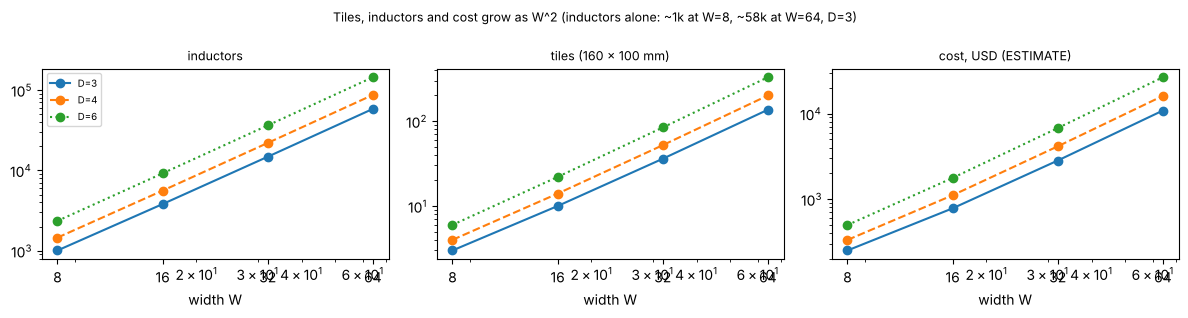

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for D, ls in ((3, "-"), (4, "--"), (6, ":")):
    d = df[df.depth == D]
    ax[0].loglog(d.width, d.inductors, "o" + ls, label=f"D={D}"); ax[1].loglog(d.width, d.tiles_total, "o" + ls); ax[2].loglog(d.width, d.cost_usd_estimate, "o" + ls)
for a, t in zip(ax, ("inductors", "tiles (160 x 100 mm)", "cost, USD (ESTIMATE)")):
    a.set_xlabel("width W"); a.set_title(t, fontsize=9); a.set_xticks([8, 16, 32, 64], ["8", "16", "32", "64"])
ax[0].legend(fontsize=7); fig.suptitle("Tiles, inductors and cost grow as W^2 (inductors alone: ~1k at W=8, ~58k at W=64, D=3)", fontsize=9); fig.tight_layout()

## 3. Accuracy against size

From the training reports (synthetic 8-class set, 4000 test examples, mixed SNR 0-20 dB). The board family is TDL-Net-B (d = 1): width 8 (all-ternary and float-readout variants), 16 and the depth-4 width-32 model. The first four rows have a quoted board scale; the width-32 TDL-Net-S (dilations 1, 4, 16) of the coax study is listed for reference but is not the board family.

 id  width  depth scaling_key     acc  acc_ge10dB  n_ternary_weights  inductors  cost_usd_estimate
 w8      8      3       W8_D3 0.80550    0.837500               1152       1008                250
w16     16      3      W16_D3 0.89900    0.938333               4352       3808                778
v32     32      4      W32_D4 0.93125    0.972083              25088      21952               4135
also: {'w8_fro (float readout)': 0.85125, 'S-family width 32 (coax study)': 0.86275, 'S-family width 8 (coax study)': 0.73475}


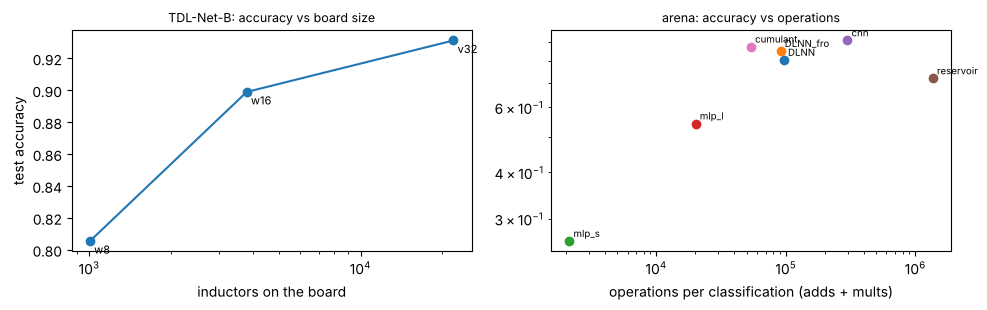

In [7]:
def rep(f, key="ternary"):
    r = paper.read_json(f); return r[key]
pts = []
for pid, f, W, D, key in (("w8", "models/tdlnet_b_w8_report.json", 8, 3, "W8_D3"), ("w16", "models/tdlnet_b_w16_report.json", 16, 3, "W16_D3"),
                          ("v32", "models/v32_modrec_report.json", 32, 4, "W32_D4")):
    t = rep(f)
    pts.append({"id": pid, "width": W, "depth": D, "scaling_key": key, "acc": t["acc"], "acc_ge10dB": t["acc_ge10dB"], "n_ternary_weights": t["n_ternary_weights"], "source": f})
acc_tab = pd.DataFrame(pts)
acc_tab["inductors"] = [COST["inductor_count_vs_width_depth"][k] for k in acc_tab.scaling_key]
acc_tab["cost_usd_estimate"] = [round(COST["scaling"][k]["cost_usd_estimate"]) if k in COST["scaling"] else None for k in acc_tab.scaling_key]
print(acc_tab.drop(columns=["source"]).to_string(index=False))
extra = {"w8_fro (float readout)": ARENA["models"]["tdlnet_b_w8_fro"]["acc"], "S-family width 32 (coax study)": rep("models/train_report_w32.json")["acc"], "S-family width 8 (coax study)": rep("models/train_report.json")["acc"]}
print("also:", extra)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].semilogx(acc_tab.inductors, acc_tab.acc, "o-"); ax[0].set_xlabel("inductors on the board"); ax[0].set_ylabel("test accuracy"); ax[0].set_title("TDL-Net-B: accuracy vs board size", fontsize=9)
for _, p in acc_tab.iterrows():
    ax[0].annotate(p["id"], (p.inductors, p.acc), fontsize=8, xytext=(3, -9), textcoords="offset points")
am = ARENA["models"]
for k in ("tdlnet_b_w8", "tdlnet_b_w8_fro", "mlp_s", "mlp_l", "cnn", "reservoir", "cumulant"):
    o = am[k]["ops"]; ax[1].loglog(o["adds"] + o["mults"], am[k]["acc"], "o"); ax[1].annotate(k.replace("tdlnet_b_w8", "DLNN"), (o["adds"] + o["mults"], am[k]["acc"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax[1].set_xlabel("operations per classification (adds + mults)"); ax[1].set_title("arena: accuracy vs operations", fontsize=9); fig.tight_layout()

## 4. Energy and latency per classification (ESTIMATE, labelled)

The part that is easiest to over-claim, so the assumptions are explicit and are the ones behind the article's `en.*` claims. **Board:** supply currents from `hw/board/params.json` (`power`: op-amp quiescent currents from datasheets, crossbar and DAC currents assumed; 1.08 W for the 3-tile demonstrator incl. carrier and Nucleo), 150 us per classification (128 samples at 1 MS/s plus about 22 us pipeline fill; the board is pipelined, so throughput is better than 1/150 us, but the energy per window is power x 150 us as the article states it). **Digital:** operations per classification from the arena report, priced with Horowitz ISSCC 2014 45 nm figures (fp32 add 0.9 pJ, fp32 multiply 3.7 pJ, a tanh = 10 multiplies; ASIC-class, a lower bound) or with the STM32G474 datasheet run-mode current (173.5 uA/MHz at 170 MHz, 3.3 V, one multiply per cycle assumed). These are orders of magnitude, not measurements.

In [8]:
hz = ENERGY["verified"][0]["pJ_per_op"]; ea, em = hz["fp_add_32bit"], hz["fp_mult_32bit"]
u_mcu = ENERGY["verified"][1]["values"]["derived_uA_per_MHz_170MHz"]
pw = paper.read_json("hw/board/params.json")["power"]
T_CLS_US = 150.0
def board_power_w(tiles_full, tiles_l1):
    p_rest = pw["p_total_system_w"] - 2 * pw["p_tile_full_w"] - 5.0 * pw["i_tile_layer1_a"]          # carrier + Nucleo + LDO, as in the 3-tile system
    return tiles_full * pw["p_tile_full_w"] + tiles_l1 * 5.0 * pw["i_tile_layer1_a"] + p_rest
def mcu_dlnn_nJ(o): return (o["adds"] * ea + o["mults"] * em + o["nonlin"] * 10 * em) / 1000
rows_e = []
for key in ("W8_D3", "W16_D3", "W32_D4"):
    t = [t for t in table if t["key"] == key][0]
    P_w = board_power_w(t["tiles_full"], t["tiles_layer1"])
    rows_e.append({"system": f"DLNN board {key} ({t['tiles_total']} tiles)", "power_W": round(P_w, 2), "latency_us": T_CLS_US, "energy_uJ": round(P_w * T_CLS_US, 1),
                   "basis": "params.json supply currents x 5 V x 150 us"})
for k in ("tdlnet_b_w8", "cnn", "mlp_l", "cumulant"):
    o = am[k]["ops"]
    rows_e.append({"system": f"{k} in fp32 on a processor", "power_W": None, "latency_us": None, "energy_uJ": round(mcu_dlnn_nJ(o) / 1000, 4),
                   "basis": f"{o['adds']} adds, {o['mults']} mults, {o['nonlin']} tanh/ReLU; Horowitz 45 nm fp32 (lower bound)"})
m_cnn = am["cnn"]["ops"]["mults"]
rows_e.append({"system": "cnn on an STM32G474 @170 MHz", "power_W": None, "latency_us": None, "energy_uJ": round(m_cnn * (u_mcu * 1e-6 / 1e6) * 3.3 * 1e6, 2),
               "basis": "one multiply per cycle at 173.5 uA/MHz, 3.3 V (datasheet IDD(Run), core + flash only)"})
et = pd.DataFrame(rows_e); print(et.to_string(index=False))
ratio = rows_e[0]["energy_uJ"] * 1000 / mcu_dlnn_nJ(am["tdlnet_b_w8"]["ops"])
print(f"\nW8_D3 board vs the same net in fp32 at 45 nm op energies: {ratio:.0f}x more energy per classification (the article's en.ratio claim).")
print("Reading: on these estimates the analog board does NOT win on energy per classification at this scale; its case is the open, reproducible four-fidelity build, not a power saving.")

                            system  power_W  latency_us  energy_uJ                                                                                 basis
        DLNN board W8_D3 (3 tiles)     1.08       150.0   162.1000                                            params.json supply currents x 5 V x 150 us
      DLNN board W16_D3 (10 tiles)     3.45       150.0   517.9000                                            params.json supply currents x 5 V x 150 us
      DLNN board W32_D4 (52 tiles)    18.28       150.0  2742.4000                                            params.json supply currents x 5 V x 150 us
tdlnet_b_w8 in fp32 on a processor      NaN         NaN     0.2093             93376 adds, 3144 mults, 3072 tanh/ReLU; Horowitz 45 nm fp32 (lower bound)
        cnn in fp32 on a processor      NaN         NaN     0.7960          151616 adds, 147528 mults, 3072 tanh/ReLU; Horowitz 45 nm fp32 (lower bound)
      mlp_l in fp32 on a processor      NaN         NaN     0.0476              10

## 5. Tolerance yield (from notebook 03)

The Monte Carlo of the P tier (inductor 5 %, capacitor 5 %, resistor 1 % uniform, clock 0.5 %, V_BE 2 mV): yield = fraction of boards with accuracy within 5 points of ideal V.

In [9]:
pt = DATA / "p_tier.json"
if pt.exists():
    mc = paper.read_json(pt)["monte_carlo"]
    print(f"stored full run: {mc['n_trials']} boards, accuracy mean {mc['accuracy_mean']:.4f}, sigma {mc['accuracy_std']:.4f}, p5 {mc['accuracy_p5']:.4f}, yield {mc['yield']:.3f} (threshold {mc['yield_threshold']})")
lite = DATA / "p_tier" / "mc.json"
if lite.exists():
    s = paper.read_json(lite)["stats"]; print(f"notebook 03 lite run: {s['n_trials']} boards, mean {s['accuracy_mean']:.4f}, yield {s['yield']:.2f}")

stored full run: 1000 boards, accuracy mean 0.8564, sigma 0.0056, p5 0.8475, yield 1.000 (threshold 0.605)
notebook 03 lite run: 50 boards, mean 0.8509, yield 1.00


## 6. Write the data files the article reads

In [10]:
ss_old = paper.read_json(EXPECTED / "data" / "scale_story.json") if (EXPECTED / "data" / "scale_story.json").exists() else None
scale_story = {"schema": "dlnn-scale-story/1", "label": COST["LABEL"], "scaling_formula": COST["scaling_formula"], "scaling": COST["scaling"],
               "inductor_only_cost_usd_at_2000_price": COST["inductor_only_cost_usd_at_2000_price"], "marginal_cost_per_tile_usd": mt,
               "accuracy_points": pts, "source": ["hw/board/cost.json", "models/tdlnet_b_w8_report.json", "models/tdlnet_b_w16_report.json", "models/v32_modrec_report.json"]}
d = COST["demonstrator_width8_3tiles"]
board_cost = {"schema": "dlnn-board-cost/1", "label": COST["LABEL"],
              "tiles": [{k: t[k] for k in ("tag", "parts_usd", "joints", "unique_parts")} for t in d["tiles"]],
              "tile_pcb_usd": d["tile_pcb_usd_for_5_boards_(3_used)"], "tile_assembly_fees_usd": d["tile_assembly_fees_usd"],
              "carrier": {k: d["carrier"][k] for k in ("parts_usd", "pcb_usd", "assembly_usd")}, "nucleo_cables_supply_usd": d["nucleo_cables_supply_usd"],
              "system_total_usd": d["system_total_usd"], "system_total_usd_with_25pct_contingency": d["system_total_usd_with_25pct_contingency"],
              "plan_claim_usd": d["plan_claim_usd"], "pcb_assumptions": COST["pcb_assumptions"]["note"]}
paper.write_json(DATA / "scale_story.json", scale_story); paper.write_json(DATA / "board_cost.json", board_cost)
paper.write_json(DATA / "scale" / "energy_estimate.json", {"schema": "dlnn-energy-estimate/1", "label": "ESTIMATE. Design numbers and 45 nm ASIC op energies, not measurements.",
                 "assumptions": {"classification_us": T_CLS_US, "power_from": "hw/board/params.json power", "fp32_add_pJ": ea, "fp32_mult_pJ": em, "stm32g474_uA_per_MHz_170MHz": u_mcu}, "rows": rows_e}, indent=1)
for name, new_obj in (("scale_story.json", scale_story), ("board_cost.json", board_cost)):
    ref = EXPECTED / "data" / name
    if ref.exists():
        print(f"{name}: identical to the reference snapshot: {paper.read_json(ref) == json.loads(json.dumps(new_obj))}")
tab = paper.show_rows(rows); assert (tab.result == "PASS").all()
paper.record_runtime("04_scale_story", time.time() - T0)
print(f"{time.time() - T0:.0f} s wall")

scale_story.json: identical to the reference snapshot: True
board_cost.json: identical to the reference snapshot: True
                                        check  got  reference  tol unit result note
scaling table reproduces cost.json (36 cells)    0          0    0        PASS     
1 s wall
